# EDA: MovieLens-1M

Цель: понять структуру данных перед сплитом и бейзлайнами

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from recsys_lab.data import load_ratings, load_movies

In [2]:
%load_ext autoreload
%autoreload 2

ratings = load_ratings()
movies = load_movies()
ratings.head()

,user_id,item_id,rating,timestamp
0,1,1193,5,2000-12-31 22:12:40
1,1,661,3,2000-12-31 22:35:09
2,1,914,3,2000-12-31 22:32:48
3,1,3408,4,2000-12-31 22:04:35
4,1,2355,5,2001-01-06 23:38:11


### A) Общая проверка

In [3]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype         
---  ------     --------------    -----         
 0   user_id    1000209 non-null  int64         
 1   item_id    1000209 non-null  int64         
 2   rating     1000209 non-null  int64         
 3   timestamp  1000209 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(3)
memory usage: 30.5 MB


In [4]:
ratings.isna().sum()

user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64

In [5]:
ratings.duplicated(["user_id", "item_id"]).sum()

np.int64(0)

In [6]:
ratings.describe() 

,user_id,item_id,rating,timestamp
count,1.000209e+06,1.000209e+06,1.000209e+06,1000209
mean,3.024512e+03,1.865540e+03,3.581564e+00,2000-10-22 19:41:35.404665
min,1.000000e+00,1.000000e+00,1.000000e+00,2000-04-25 23:05:32
25%,1.506000e+03,1.030000e+03,3.000000e+00,2000-08-03 11:37:17
50%,3.070000e+03,1.835000e+03,4.000000e+00,2000-10-31 18:46:46
75%,4.476000e+03,2.770000e+03,4.000000e+00,2000-11-26 06:42:19
max,6.040000e+03,3.952000e+03,5.000000e+00,2003-02-28 17:49:50
std,1.728413e+03,1.096041e+03,1.117102e+00,NaN


Как видно: 
- пропусков и дубликатов нет
- оценки: целые числа от 1 до 5.
- user_id: от 1 до 6040
- item_id: от 1 до 3952
- временной промежуток: от 2000-04-25 23:05:32 до 2003-02-28 17:49:50. При этом 75% оценок - до 2000-11-26 06:42:19

В целом, данные в готовом виде и нет необходимости в какой-либо чистке

### B) Структура взаимодействий

1) Посмотрим на размер и разреженность

In [7]:
n_users = ratings["user_id"].nunique()
n_items = ratings["item_id"].nunique()
density = len(ratings) / (n_users * n_items)  # доля заполненных клеток
print(f"{len(ratings)} оценок, {n_users} пользователей, {n_items} фильмов")
print(f"заполнено {density:.2%}, sparsity {1 - density:.4f}")

1000209 оценок, 6040 пользователей, 3706 фильмов
заполнено 4.47%, sparsity 0.9553


Заполнено только 4.47% матрицы userxitem, матрица разреженная -> значит матрицу взаимодействий храним в scipy.sparse, чтобы сэкономить место

Также: у нас 3706 фильмов, а максимальный item_id это 3952, значит есть пропуски, т.е. перед построением надо бы перенумеровать id для item-ов

2) Посмотрим на распределения оценок, которые поставили пользователи

In [8]:
ratings["rating"].value_counts(normalize=True).sort_index()

rating
1    0.056162
2    0.107535
3    0.261142
4    0.348898
5    0.226263
Name: proportion, dtype: float64

In [9]:
print(f"Доля оценок 4 и 5: {(ratings["rating"] >= 4).mean():.2%}")

Доля оценок 4 и 5: 57.52%


Как видно, оценки смещены вверх и хорошие оценки составляют более половины всего взаимодействия, что имеет смысл, т.к. пользователи обычно смотрят то, что сами выбрали

3) Посмотрим, сколько оценок у типичного пользователя и есть ли сверхактивные

In [10]:
user_act = ratings.groupby("user_id").size()
user_act.describe()

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
dtype: float64

Типичный (медианный) пользователь поставил 96 оценок, среднее: 165, минимальное число оценок: 20, при этом есть пользователь с 2314 оценками, что очень сильно отличается от медианного значения.
Небольшое количество значение активных пользователей дают большую долю оценок.

Значит:
- метрики будем усреднять по пользователям, иначе их определят самые активные
- в обучении активные пользователи будут доминировать

4) Посмотрим, насколько оценки сосредоточены на небольшом числе фильмов

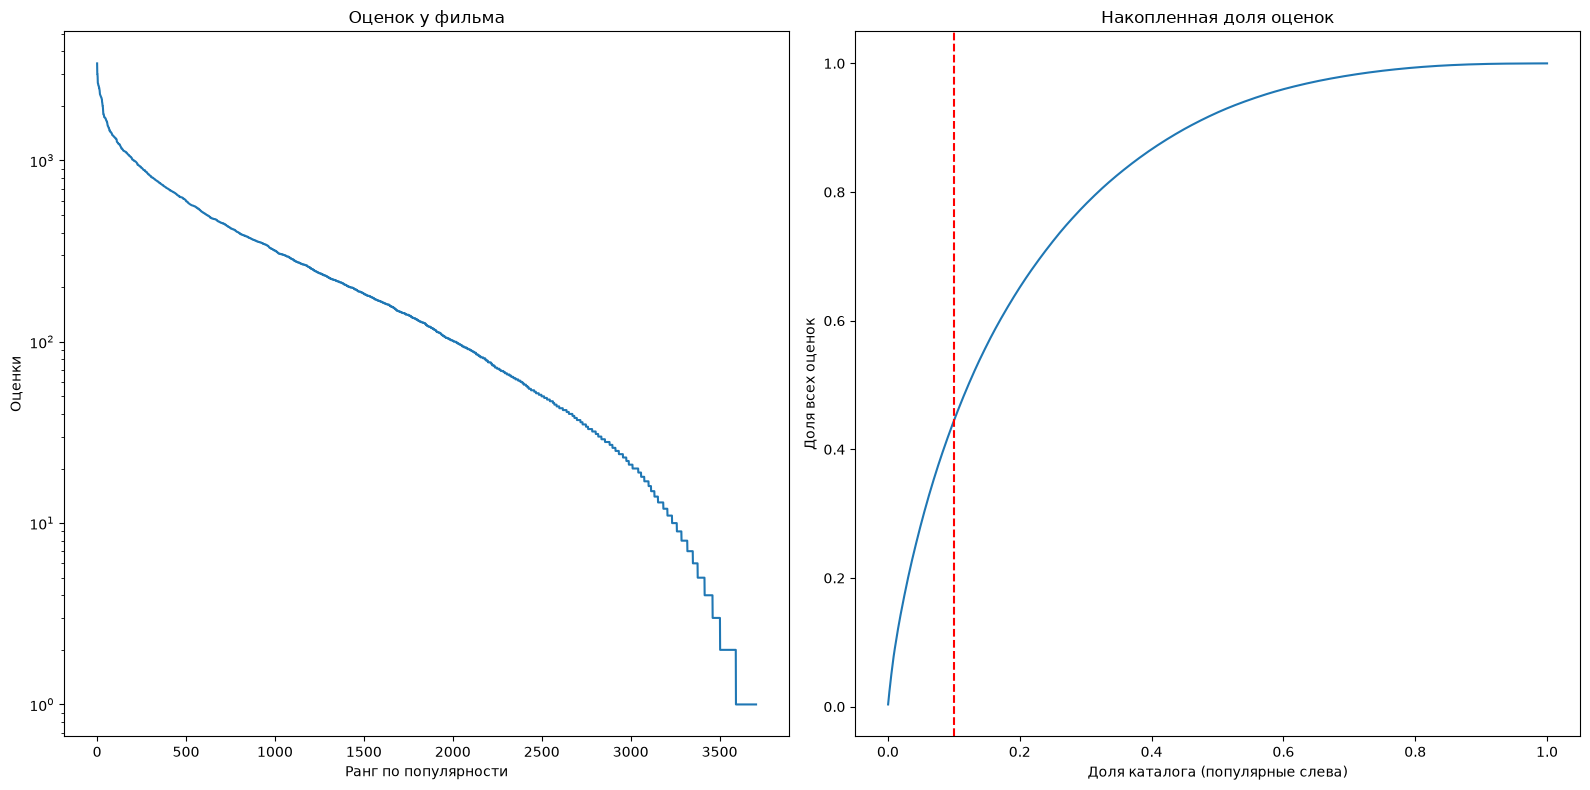

In [11]:
item_pop = ratings.groupby("item_id").size().sort_values(ascending=False)

rating_counts = item_pop.to_numpy()
catalog_share = np.arange(1, len(rating_counts) + 1) / len(rating_counts)
cum_share = rating_counts.cumsum() / rating_counts.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

ax1.plot(rating_counts)
ax1.set_yscale("log")
ax1.set(title="Оценок у фильма", xlabel="Ранг по популярности", ylabel="Оценки")

ax2.plot(catalog_share, cum_share)
ax2.axvline(0.1, ls="--", c="red")
ax2.set(title="Накопленная доля оценок", xlabel="Доля каталога (популярные слева)", ylabel="Доля всех оценок")

plt.tight_layout()
plt.show()

In [12]:
top10 = item_pop.head(len(item_pop) // 10).sum() / len(ratings)
last10 = item_pop.tail(len(item_pop) // 10).sum() / len(ratings)
print(f"Топ-10% фильмов собирают {top10:.2%} оценок")
print(f"Последние 10% фильмов собирают {last10:.2%} оценок")

Топ-10% фильмов собирают 44.38% оценок
Последние 10% фильмов собирают 0.11% оценок


In [13]:
item_pop.head(10).to_frame("n").join(movies.set_index("item_id")["title"])  # топ-10 с названиями

,n,title
item_id,,
2858,3428,American Beauty (1999)
260,2991,Star Wars: Episode IV - A New Hope (1977)
1196,2990,Star Wars: Episode V - The Empire Strikes Back...
1210,2883,Star Wars: Episode VI - Return of the Jedi (1983)
480,2672,Jurassic Park (1993)
2028,2653,Saving Private Ryan (1998)
589,2649,Terminator 2: Judgment Day (1991)
2571,2590,"Matrix, The (1999)"
1270,2583,Back to the Future (1985)


Топ 10% фильмов собирают 44% оценок, при этом последние 10% - только 0.11% оценок. Значит предлагая всем топ фильмов мы уже будем попадать во вкусы многих, а значит имеет смысл будущие модели сравнивать с popular-бейзлайном. 

Модели будут склонны к перекосу в сторону популярного, поэтому кроме точности будем считать coverage

Для фильмов из хвоста (последние 10%) данных мало, для них коллаборативные модели будут работать плохо

5) Посмотрим, насколько равномерно собраны оценки по времени

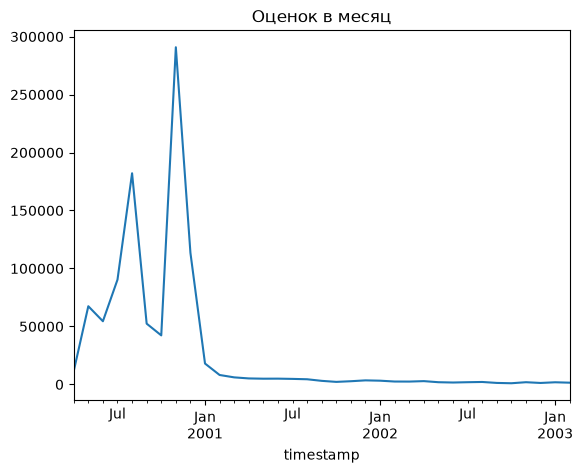

In [14]:
ratings["timestamp"].dt.to_period("M").value_counts().sort_index().plot(title="Оценок в месяц")
plt.show()

In [15]:
ratings["timestamp"].quantile([0.5, 0.8, 0.9, 0.95])

0.50   2000-10-31 18:46:46.000
0.80   2000-12-02 14:52:18.000
0.90   2000-12-29 23:42:56.400
0.95   2001-06-20 21:55:52.600
Name: timestamp, dtype: datetime64[us]

Как видим, несмотря на то, что данные собраны с 25.04.2000 по 28.02.2003, 90% данных приходится на 2000 год, а остальные 10% растянуты на 2 с лишним года.

Порог разбиения train/test ставим по квантилю времени по оценкам, а не по самим датам 

6) Посмотрим, ставят ли пользователи оценки по одной или сразу пачками?

In [16]:
same_ts = ratings.duplicated(["user_id", "timestamp"]).mean()
first_time = ratings.groupby("user_id")["timestamp"].transform("min")
day1 = (ratings["timestamp"] - first_time <= pd.Timedelta(days=1)).mean()
print(f"В ту же секунду, что и другая оценка юзера: {same_ts:.0%}")
print(f"В первые сутки после первой оценки: {day1:.0%}")

В ту же секунду, что и другая оценка юзера: 53%
В первые сутки после первой оценки: 72%


Как видно, 53% оценок поставлены в ту же секунду, что и другая оценка пользователя, а 72% - в первые сутки после первой оценки. То есть пользователи выставляют оценки не сразу после просмотра, а пачками. 

Значит порядок оценок ненадежен и это ограничение для использования последовательных моделей.

Также при разбиении по времени история оценок пользователей с высокой вероятностью окажется по одну сторону порога, а кто зарегистрировался после порога - в обучение не попадет и окажется в test холодным

## Выводы

Данные чистые: пропусков и дубликатов нет, чистка не нужна. 

Решения для пайплайна:

1. Взаимодействием считаем любую оценку + отдельным экспериментом только позитивную (4-5)
2. Используем scipy.sparse, т.к. матрица разрежена + перенумеровываем id фильмов, т.к. в них есть пропуски
3. Активность пользователей неравномерна, поэтому усредняем по пользователям. Сильный перекос в популярное, поэтому кроме точности считаем coverage
4. Любую модель сравниваем с popular-бейзлайном, т.к. 10% популярных собирают 44% оценок
5. Порог train/test делаем по квантилю времени, т.к. 90% оценок поставлены до конца 2000 года. Из-за этого в test будут холодные пользователи (72% оценок пользователя появляются в первые сутки)- их оцениваем отдельно и рекомендуем им популярное»
6. Порядок оценок внутри пользователя ненадёжен, это важно для моделей, которые учитывают порядок